<center><h1> IFT-6758  Data Science  </h1></center>
<center><h2> Fall - 2020 </h2></center>
<center><h3> Lab - 6</h3></center>
<center><h3> </h3></center>
<center><h3>Putting-it-all-together</h3></center>

# Data Science Pipeline

<img src='https://miro.medium.com/max/1400/1*CyK1miQfy1OHmv2wUcjT1w.png'>

# Inspecting Titanic Dataset


[Titanic Kaggle Competition](https://www.kaggle.com/c/titanic/overview)


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

#### Download the dataset files

In [2]:
!wget -q https://raw.githubusercontent.com/Jhelum-Ch/DataScience_IFT6758/gh-pages/media/titanic-train.csv -O train.csv
!wget -q https://raw.githubusercontent.com/Jhelum-Ch/DataScience_IFT6758/gh-pages/media/titanic-test.csv -O test.csv

#### Load the data into DataFrames

In [3]:
df_train = pd.read_csv("train.csv")
df_test = pd.read_csv("test.csv")

#### Get DataFrame info

In [4]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


**pclass**: A proxy for socio-economic status (SES)
1st = Upper
2nd = Middle
3rd = Lower

**age**: Age is fractional if less than 1. If the age is estimated, is it in the form of xx.5

**sibsp**: The dataset defines family relations in this way...
Sibling = brother, sister, stepbrother, stepsister
Spouse = husband, wife (mistresses and fiancés were ignored)

**parch**: The dataset defines family relations in this way...
Parent = mother, father
Child = daughter, son, stepdaughter, stepson
Some children travelled only with a nanny, therefore parch=0 for them.

In [5]:
df_train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


How many feature variables to we have?

Which is the target variable here?

#### Inspect for null values

In [6]:
df_train.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [7]:
# df_test.isnull().sum()

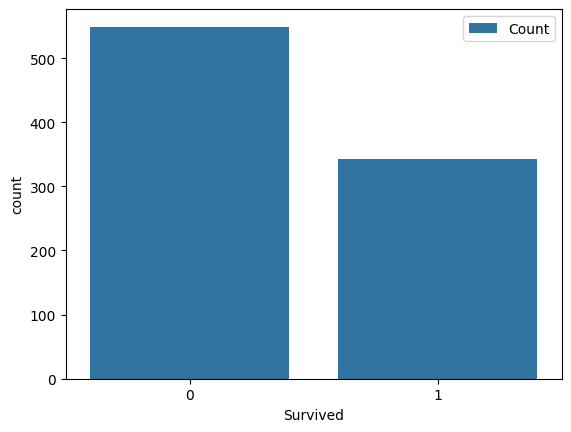

In [8]:
#Visualize the count of number of survivors
sns.countplot(x='Survived', label="Count", data=df_train);

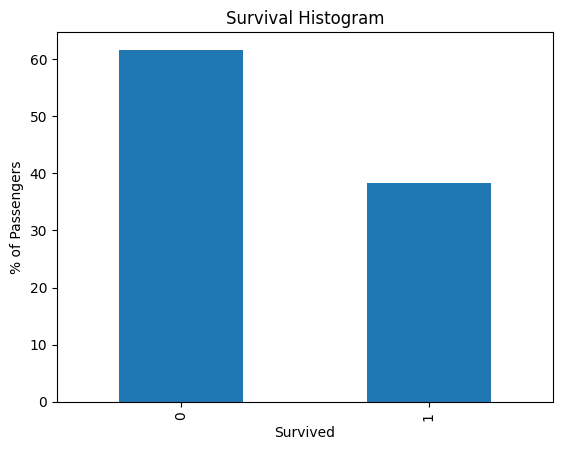

In [9]:
(df_train["Survived"].value_counts(normalize=True)*100).plot(kind="bar")
plt.title("Survival Histogram")
plt.ylabel("% of Passengers")
plt.xlabel("Survived")
plt.show();

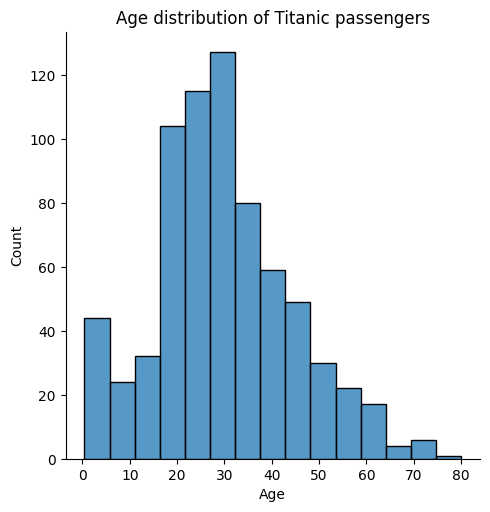

In [10]:
sns.displot(df_train['Age'].dropna(), bins=15, kde=False)
plt.ylabel('Count')
plt.title('Age distribution of Titanic passengers');

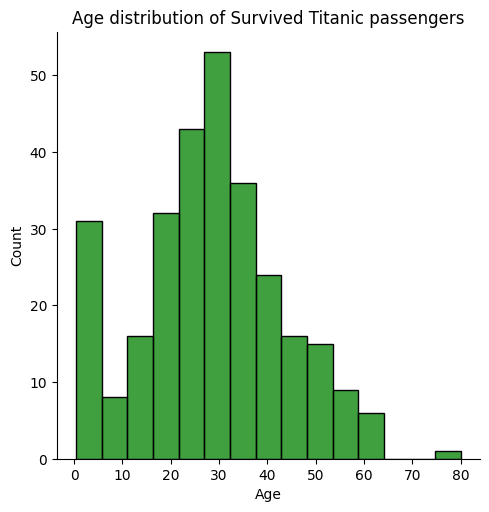

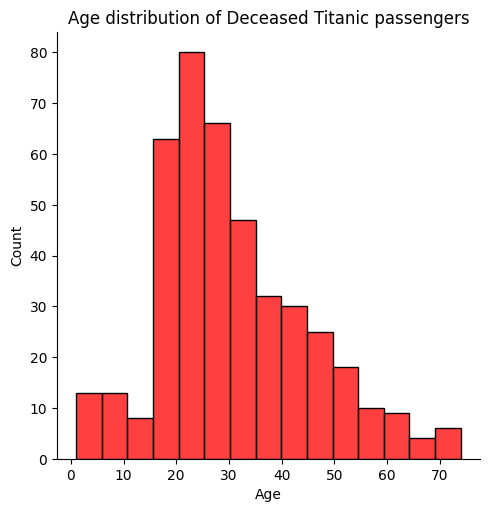

In [11]:
sns.displot(df_train[df_train['Survived']==1]['Age'].dropna(), bins=15, kde=False, color='green')
plt.title('Age distribution of Survived Titanic passengers');
sns.displot(df_train[df_train['Survived']==0]['Age'].dropna(), bins=15, kde=False, color='red')
plt.ylabel('Count')
plt.title('Age distribution of Deceased Titanic passengers');

/tmp/ipython-input-1978906443.py:1: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  g = sns.kdeplot(df_train["Age"][df_train["Survived"] == 0], label="Perished", shade=True, color="red")
/tmp/ipython-input-1978906443.py:2: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  g = sns.kdeplot(df_train["Age"][df_train["Survived"] == 1], label="Survived", shade=True, color="green")


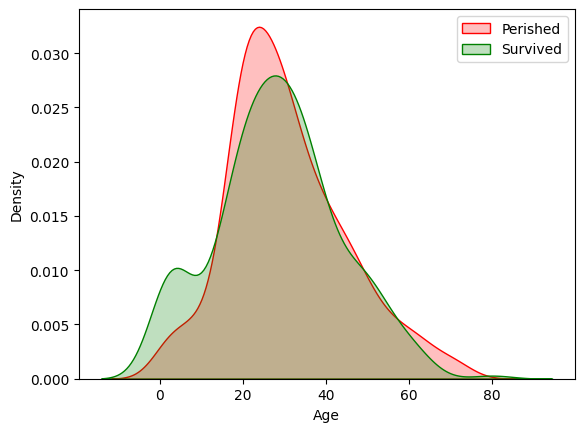

In [12]:
g = sns.kdeplot(df_train["Age"][df_train["Survived"] == 0], label="Perished", shade=True, color="red")
g = sns.kdeplot(df_train["Age"][df_train["Survived"] == 1], label="Survived", shade=True, color="green")
plt.xlabel("Age")
plt.ylabel("Density")
plt.legend()
plt.show()

#### Exploring outliers

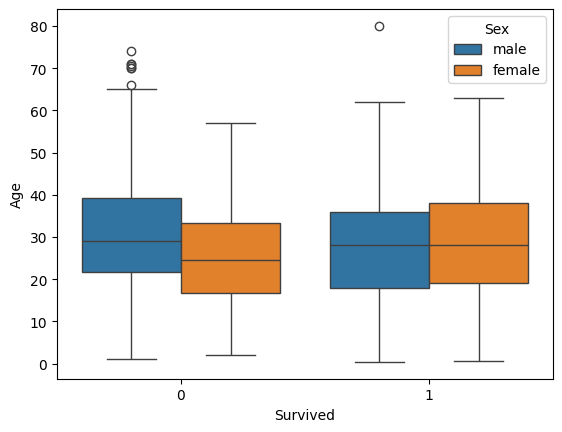

In [13]:
sns.boxplot(x='Survived',y='Age',hue='Sex',data=df_train);

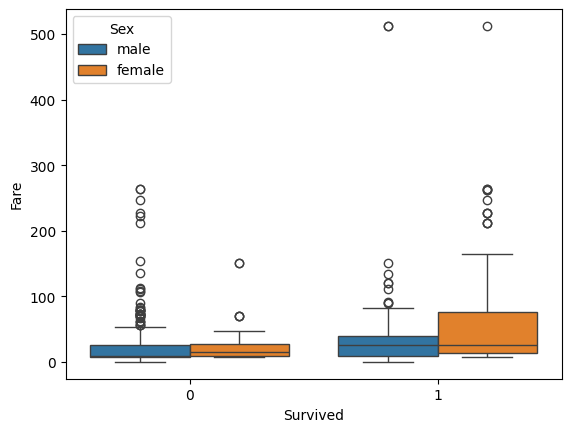

In [14]:
sns.boxplot(x='Survived',y='Fare',hue='Sex',data=df_train);

In [15]:
# Heatmap for feature variance

plt.figure(figsize=(12,10))
sns.heatmap(df_train.drop('PassengerId',axis=1).corr(), vmax=0.6, square=True, annot=True);

ValueError: could not convert string to float: 'Braund, Mr. Owen Harris'

<Figure size 1200x1000 with 0 Axes>

# Feature Engineering


### Feature 1: PClass

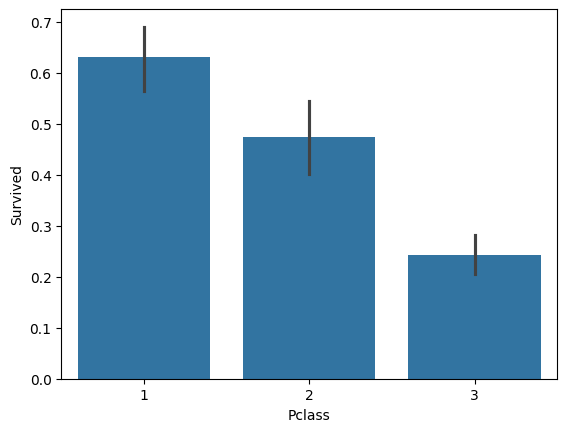

In [16]:
# Comparing Social class with survival rate
sns.barplot(x='Pclass', y='Survived', data=df_train);

In [17]:
## Converting pclass into three separate boolean variables
dummy_pclass = pd.get_dummies(df_train.Pclass, prefix='Pclass')
dummy_pclass.head()

,Pclass_1,Pclass_2,Pclass_3
0,False,False,True
1,True,False,False
2,False,False,True
3,True,False,False
4,False,False,True


In [18]:
# Merging these new classes with the main data.
df_train = df_train.merge(dummy_pclass, left_index=True, right_index=True)
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
 12  Pclass_1     891 non-null    bool   
 13  Pclass_2     891 non-null    bool   
 14  Pclass_3     891 non-null    bool   
dtypes: bool(3), float64(2), int64(5), object(5)
memory usage: 86.3+ KB


### Feature 2: Sex

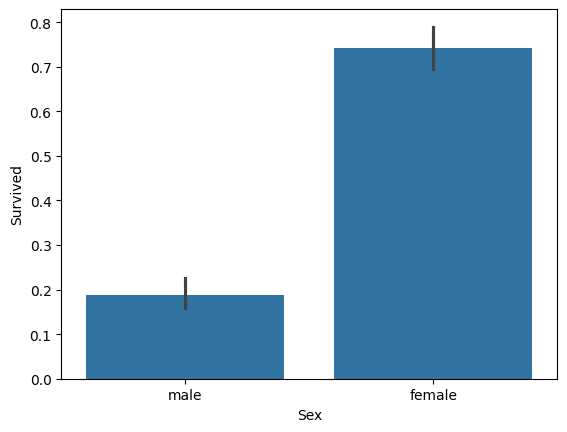

In [19]:
# Relation of gender with survival rate
sns.barplot(x='Sex', y='Survived', data=df_train);

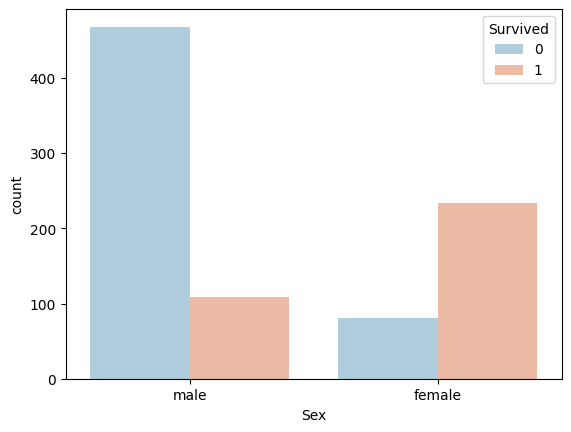

In [20]:
# Another way to look at the same data.
sns.countplot(x='Sex', hue='Survived', data=df_train, palette='RdBu_r');

In [21]:
df_train.Sex.replace(['male', 'female'], ['1', '0'], inplace=True)

/tmp/ipython-input-3681291395.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_train.Sex.replace(['male', 'female'], ['1', '0'], inplace=True)


### Feature 3: Cabin

In [22]:
df_train['Cabin']

,Cabin
0,NaN
1,C85
2,NaN
3,C123
4,NaN
...,...
886,NaN
887,B42
888,NaN
889,C148


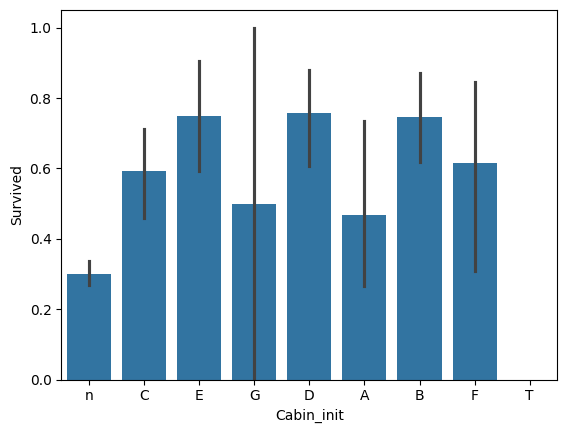

In [23]:
# Splitting the first letter to get class of the Cabin
df_train['Cabin_init'] = df_train['Cabin'].apply(lambda x : str(x)[0])
sns.barplot(x='Cabin_init', y='Survived', data=df_train);

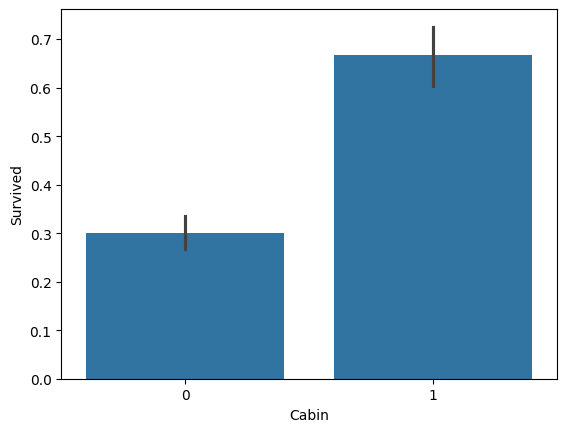

In [24]:
# Using NaN value as an information for the model.
df_train.loc[df_train.Cabin.notnull(), 'Cabin']=1
df_train.loc[df_train.Cabin.isnull(), 'Cabin']=0
sns.barplot(x='Cabin', y='Survived', data=df_train);

### Feature 4: Age

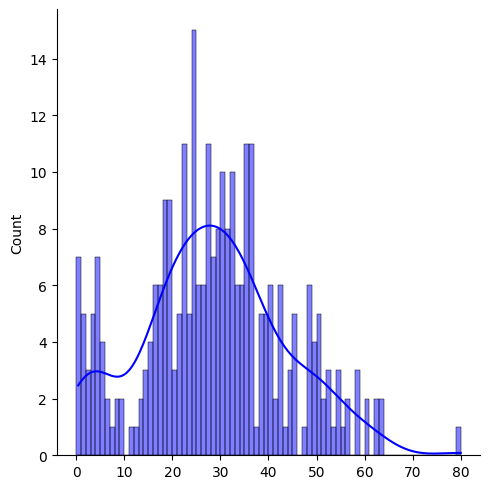

In [25]:
surv = df_train[df_train['Survived']==1]
sns.displot(surv['Age'].dropna().values, bins=range(0, 81, 1), kde=True, color='blue');

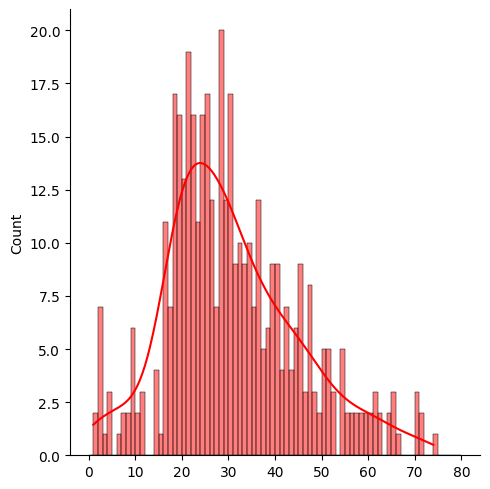

In [26]:
nosurv = df_train[df_train['Survived']==0]
sns.displot(nosurv['Age'].dropna().values, bins=range(0, 81, 1), kde=True, color='red');

# Exercise

#### Q1 - Imputation
**Imputation for null values in "Age".**   
Hint: One could simply replace it with the mean value or get creative and guess the correct age with the title in the `Name`.

In [27]:
## Replace this with a better technique
df_train.Age = df_train.Age.fillna(-0.5)


/tmp/ipython-input-966185645.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  average_age = df_train[["Age", "Survived"]].groupby(['Age'],as_index=False).mean()


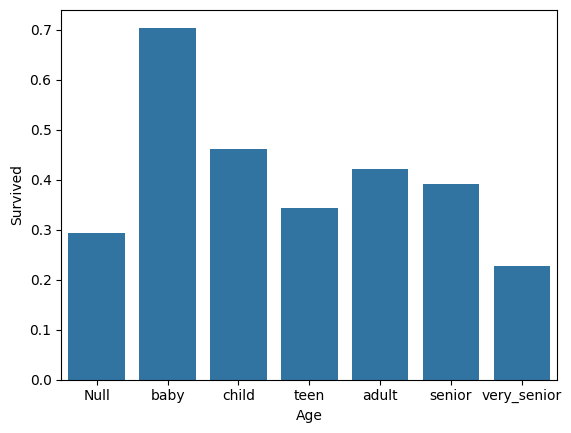

In [28]:
df_train.Age = pd.cut(df_train.Age, (-1, 0, 5, 15, 25, 40, 60,120),
                        labels=["Null", "baby","child", "teen", "adult", "senior", "very_senior"])

average_age = df_train[["Age", "Survived"]].groupby(['Age'],as_index=False).mean()
sns.barplot(x='Age', y='Survived', data=average_age);

### Feature 5: Family




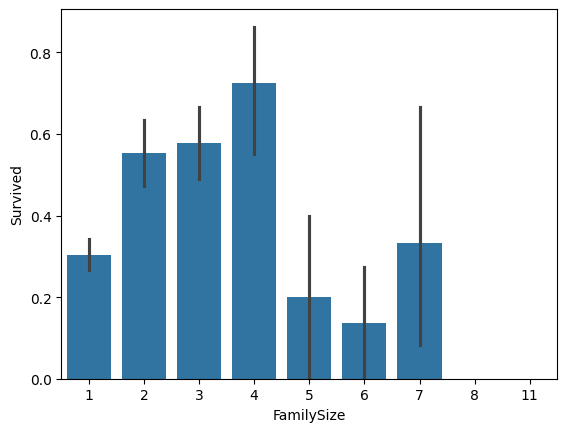

In [29]:
# Combining Siblings with Parents to get family size?
df_train['FamilySize'] = df_train['SibSp'] + df_train['Parch'] + 1
sns.barplot(x='FamilySize', y='Survived', data=df_train);

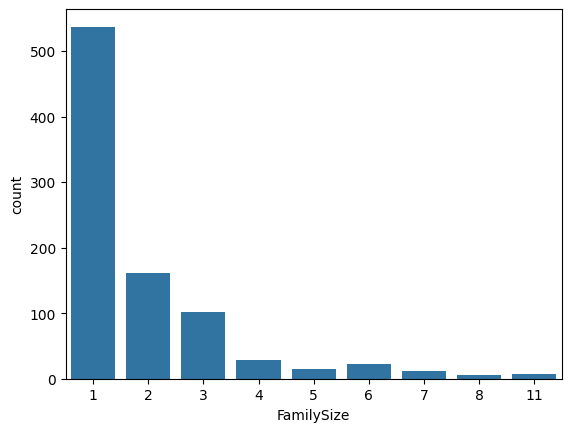

In [30]:
sns.countplot(x='FamilySize', data=df_train);

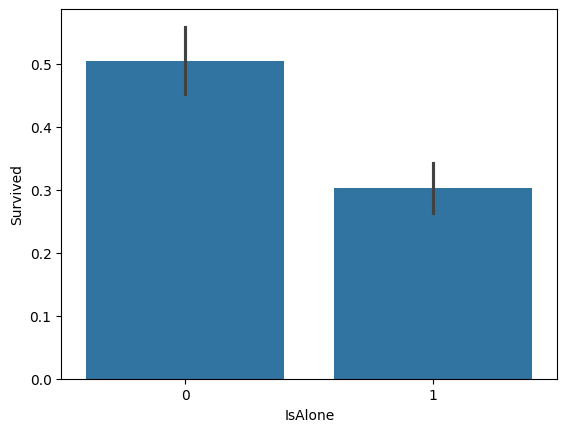

In [31]:
# The data is so skewed. Why not further modify it as a new column?
# A person without a family has lower chance of survival
df_train['IsAlone'] = 0
df_train.loc[df_train['FamilySize'] == 1, 'IsAlone'] = 1
sns.barplot(x='IsAlone', y='Survived', data=df_train);

### Feature 6: Embarked

In [32]:
df_train.groupby('Embarked').Survived.value_counts()

Embarked  Survived
C         1            93
          0            75
Q         0            47
          1            30
S         0           427
          1           217
Name: count, dtype: int64

### Feature 7,8,9
Modify these features as part of your exercise  
7.   Fare
8.   Name
9.   Ticket


# Exercise

#### Q2: Cleaning
Do Feature Engineering for the above 3 features and include them in the training data to further boost your accuracy.

# Pre-Processing


In [33]:
# Finalizing all the pre-processing steps we have seen above.
def pre_process(data):
  data['Sex'].replace(['male', 'female'], ['1', '0'], inplace=True)
  data = data.merge(pd.get_dummies(data['Pclass'], prefix='Pclass'), left_index=True, right_index=True)

  data.loc[data.Cabin.notnull(), 'Cabin']=1
  data.loc[data.Cabin.isnull(), 'Cabin']=0

  data.Age = pd.cut(data.Age.fillna(-0.5), (-1, 0, 5, 15, 25, 40, 60,120),
                        labels=[0, 1, 2, 3, 4, 5, 6])

  data['Embarked'] = data['Embarked'].fillna('S').replace(['C', 'Q', 'S'], ['1', '2', '3'])
  data['FamilySize'] = data['SibSp'] + data['Parch'] + 1
  data['IsAlone'] = 0
  data.loc[data['FamilySize'] == 1, 'IsAlone'] = 1
  return data


df_train = pre_process(pd.read_csv("/content/train.csv"))
df_test = pre_process(pd.read_csv("/content/test.csv"))

cols_x = ['Sex', 'Age', 'Cabin', 'Pclass_1', 'Pclass_2', 'Pclass_3', 'Embarked', 'IsAlone']
## Add other features like ['Fare', 'Name', 'Ticket] after completing Q2
cols_y = 'Survived'

/tmp/ipython-input-1820237318.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data['Sex'].replace(['male', 'female'], ['1', '0'], inplace=True)
/tmp/ipython-input-1820237318.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inpla

#Exercise

#### Q3 : PCA

(a) Perform a PCA on this preprocessed set of features (include different fields and try) and visualize them in 2D and/or 3D to see if it helps classify the data.

(b) Use a 90% variance PCA transformed features to fit a logistic regression model and see how it performs.

Do you think applying PCA is a good choice for this case?**bold text**

# Fit Model

In [34]:
from sklearn.model_selection import train_test_split

# split dataset to train and test
X_train, X_test, y_train, y_test = train_test_split(df_train[cols_x], df_train[cols_y],
                                                    test_size=0.3,
                                                    shuffle=True,
                                                    random_state=76 #  To guarantee that the split will always be the same
                                                    )

In [35]:
from sklearn.tree import DecisionTreeClassifier
cls = DecisionTreeClassifier()
cls.fit(X_train, y_train)
cls.score(X_test, y_test)

0.8022388059701493

# Hyperparameters tuning


In [36]:
# Machine Learning
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import Perceptron
from sklearn.svm import SVC, LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn import tree

# Ensembling
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import VotingClassifier

# Metrics
from sklearn import preprocessing
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import KFold
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix

#### Initialization

In [37]:
result = pd.DataFrame(columns = ("Classifiers","Training","Testing"))
classifier, train_scores, test_scores = [],[],[]

#### Decision Tree

In [38]:
clf_tree = tree.DecisionTreeClassifier(
    #max_depth=3,\
    class_weight="balanced",\
    min_weight_fraction_leaf=0.01\
    )
clf_tree = clf_tree.fit(X_train,y_train)
classifier.append("DecisionTreeClassifier")
train_scores.append(clf_tree.score(X_train, y_train))
test_scores.append(clf_tree.score(X_test, y_test))

#### Logistic Regression

In [39]:
clf_log = LogisticRegression()
clf_log = clf_log.fit(X_train,y_train)
classifier.append("LogisticRegression")
train_scores.append(clf_log.score(X_train, y_train))
test_scores.append(clf_log.score(X_test, y_test))

# pd.DataFrame(list(zip(X_train.columns, np.transpose(clf_log.coef_))))

TypeError: can't multiply sequence by non-int of type 'float'

#### KNN

In [ ]:
knn = KNeighborsClassifier(n_neighbors = 3)
knn.fit(X_train, y_train)
classifier.append("KNeighborsClassifier")
train_scores.append(knn.score(X_train, y_train))
test_scores.append(knn.score(X_test, y_test))

#### Support Vector Classifier

In [ ]:
cf = SVC()
cf.fit(X_train, y_train)
classifier.append("SVM")
train_scores.append(cf.score(X_train, y_train))
test_scores.append(cf.score(X_test, y_test))

#### Perceptron

In [ ]:
clf_pctr = Perceptron(
    class_weight='balanced'
    )
clf_pctr = clf_pctr.fit(X_train,y_train)
classifier.append("Perceptron")
train_scores.append(clf_pctr.score(X_train, y_train))
test_scores.append(clf_pctr.score(X_test, y_test))

#### Random Forest

In [ ]:
random_forest = RandomForestClassifier(n_estimators=100)
random_forest.fit(X_train, y_train)
classifier.append("RandomForestClassifier")
train_scores.append(random_forest.score(X_train, y_train))
test_scores.append(random_forest.score(X_test, y_test))

#### Extra Tree

In [ ]:
clf_ext = ExtraTreesClassifier(
    max_features='auto',
    bootstrap=True,
    oob_score=True,
    n_estimators=1000,
    max_depth=None,
    min_samples_split=10
    #class_weight="balanced",
    #min_weight_fraction_leaf=0.02
    )
clf_ext = clf_ext.fit(X_train,y_train)
classifier.append("ExtraTreesClassifier")
train_scores.append(clf_ext.score(X_train, y_train))
test_scores.append(clf_ext.score(X_test, y_test))

#### Ada Boost

In [ ]:
clf_ada = AdaBoostClassifier(n_estimators=400, learning_rate=0.1)
clf_ada.fit(X_train,y_train)
classifier.append("AdaBoostClassifier")
train_scores.append(clf_ada.score(X_train, y_train))
test_scores.append(clf_ada.score(X_test, y_test))

#### Results

In [ ]:
for i,text in enumerate(classifier):
    result.loc[i+1] = [text,np.around(train_scores[i]*100, decimals = 1),np.around(test_scores[i]*100, decimals=1)]
result

# Ensemble Methods

In [ ]:
# Trying to improve with the ensemble of all predictors

clf_vote = VotingClassifier(
    estimators=[
        ('knn', knn), # KNN
        ('svm', cf), # SVM
        ('dt', clf_tree), # Decision Tree
        ('extra', clf_ext), #  Extra Tree
        ('logistic', clf_log), # Logistic Regression
        ('adaboost', clf_ada)
        ],
    weights=[1, 1, 1, 1, 1, 1],
    voting='hard')
clf_vote.fit(X_train, y_train)
clf_vote.score(X_test, y_test)

# Cross Validation

In [ ]:
scores = cross_val_score(clf_vote, df_train[cols_x], df_train[cols_y], cv=5, scoring='accuracy')
print("Voting: Accuracy: %0.2f (+/- %0.2f)" % (scores.mean(), scores.std()))

# Submission File

In [ ]:
clf_vote.fit(df_train[cols_x], df_train[cols_y])
y_pred = clf_vote.predict(df_test[cols_x])

In [ ]:
dummy = pd.DataFrame()
dummy["PassengerId"] = df_test["PassengerId"]
dummy["Survived"]=clf_vote.predict(df_test[cols_x])
dummy.to_csv("submission.csv", sep=',' ,index=False)

This submission file gives an accuracy of 76% at https://www.kaggle.com/c/titanic/submit

# Exercise:

Q4. Do a "RandomGridSearchCV" on the algorithm of your choice and find the best sets of Hyper params.  
  

#Exercise :

Q5. Use all the techniques we have studied until now for feature selection / extraction / engineering and improve the submission accuracy to 80+

*Hints*:
1. Use One-Hot vector for features.
2. Use Normalization/Standardization
3. Feature selection using covariance with target labels.
4. Use domain knowledge to extract relevant information from the given features.
5. Try Stacking?


#Exercise :


Q6. For the final trained ensemble classifier above, evaluate the model performance with bootstrapping and compute the confidence interval for the accuracy using the training set. Does this compare well with the score you obtain from the Kaggle submission?

## REFERENCES

[1] [Comprehensive tutorials for Housing dataset](https://www.kaggle.com/c/house-prices-advanced-regression-techniques/overview/tutorials)

[2] [Titanic Prediction blog post](https://towardsdatascience.com/predicting-the-survival-of-titanic-passengers-30870ccc7e8)

[3] [Titanic EDA](https://becominghuman.ai/titanic-survival-dataset-part-1-2-exploratory-data-analysis-5b98f7917913)

[4] [How to almost win Kaggle competitions? - Yanir Seroussi](https://yanirseroussi.com/2014/08/24/how-to-almost-win-kaggle-competitions/)

[5] [Blog post on Tips and Tricks to succeed on Kaggle](https://www.dataquest.io/blog/kaggle-tips-tricks/)